In [ ]:
pip install numpy matplotlib librosa soundfile scipy

In [20]:
import os
print(os.listdir('Electroverse-Week2-Challenge'))

['ps_solution.ipynb', 'tester', 'README.md', '.git', 'songs']



Song: IlluminatiAaveshamJithu MadhavanFahadh FaasilSushin Shyam,Dabzee,Vinayak NazriyaAnwar Rasheed - Think Music India.mp3
Sample rate: 22050 Hz
Duration: 148.22 seconds
Channels after conversion: 1
Number of samples: 3268340

Song: Sunflower (Spider-Man Into the Spider-Verse) - Post Malone.mp3
Sample rate: 22050 Hz
Duration: 158.06 seconds
Channels after conversion: 1
Number of samples: 3485312

Song: [4K] Rang-(Way Down We Go) - Spoof.mp3
Sample rate: 22050 Hz
Duration: 96.41 seconds
Channels after conversion: 1
Number of samples: 2125797


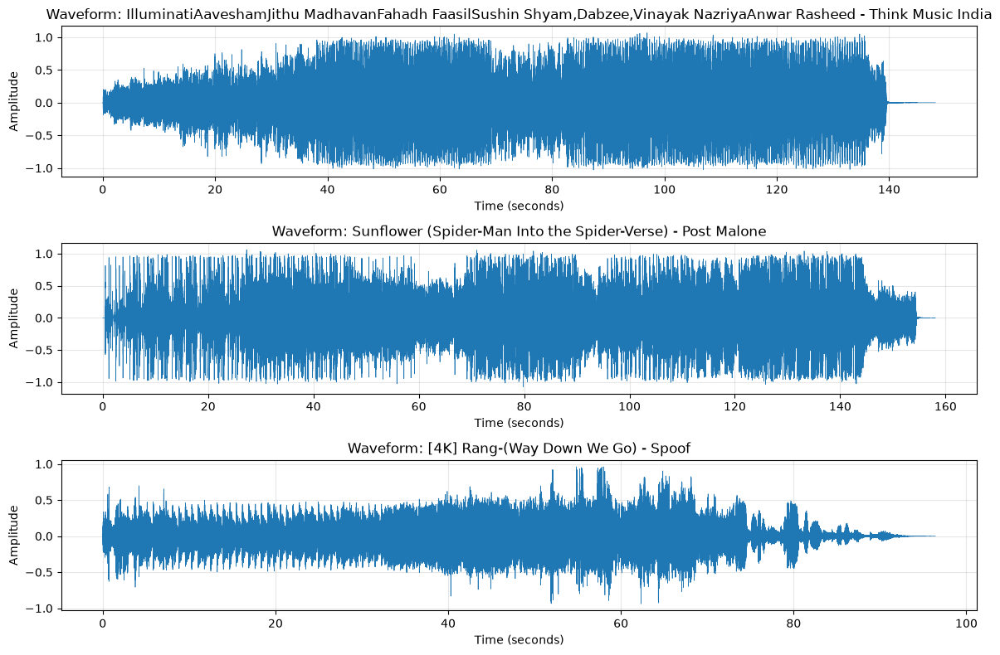

In [12]:

from pathlib import Path

import librosa
import numpy as np
import matplotlib.pyplot as plt

# Consistent format for all songs
TARGET_SR = 22050


def load_audio(file_path, target_sr=TARGET_SR):
    """
    Load an audio file and convert it to mono
    at a consistent sample rate.
    """
    audio, sr = librosa.load(
        file_path,
        sr=target_sr,
        mono=True
    )

    duration = len(audio) / sr

    return audio, sr, duration


# Locate the three songs
audio_files = sorted(
    Path("songs").glob("*")
)

audio_files = [
    f for f in audio_files
    if f.suffix.lower() in {
        ".mp3", ".wav", ".flac",
        ".ogg", ".m4a", ".aiff"
    }
]

if len(audio_files) != 3:
    raise ValueError(
        f"Expected 3 audio files, found {len(audio_files)}."
    )

songs = {}

for file_path in audio_files:
    audio, sr, duration = load_audio(file_path)

    songs[file_path.stem] = audio

    print(f"\nSong: {file_path.name}")
    print(f"Sample rate: {sr} Hz")
    print(f"Duration: {duration:.2f} seconds")
    print(f"Channels after conversion: 1")
    print(f"Number of samples: {len(audio)}")


# Plot the three waveforms
fig, axes = plt.subplots(
    3, 1, figsize=(12, 8)
)

for ax, (name, audio) in zip(
    axes, songs.items()
):
    time = np.arange(len(audio)) / TARGET_SR

    ax.plot(time, audio, linewidth=0.5)
    ax.set_title(f"Waveform: {name}")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


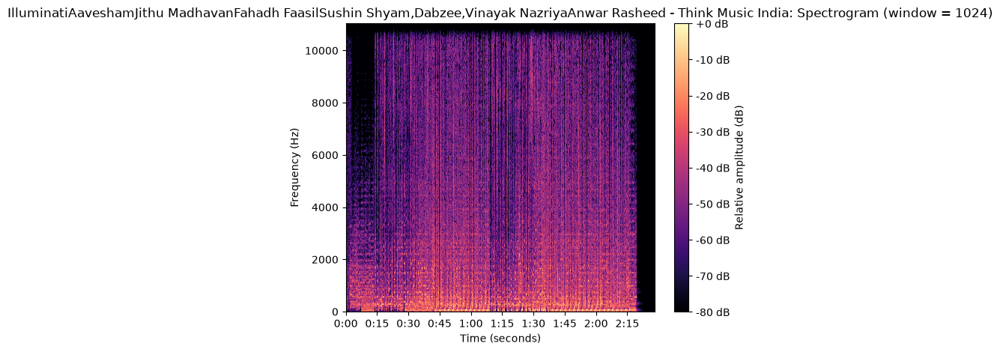

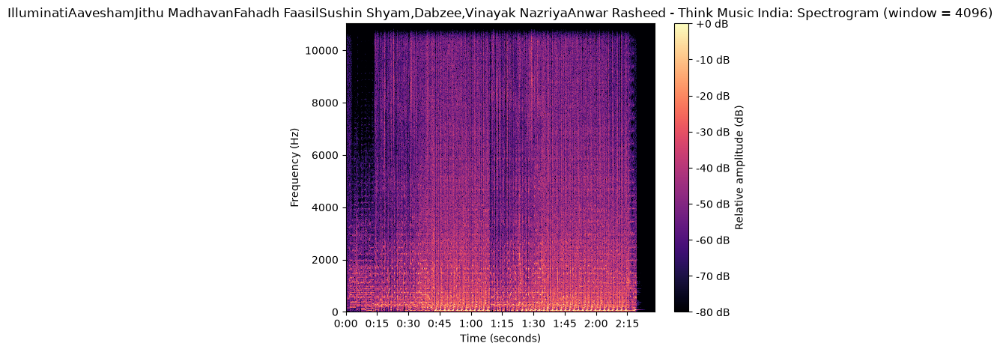

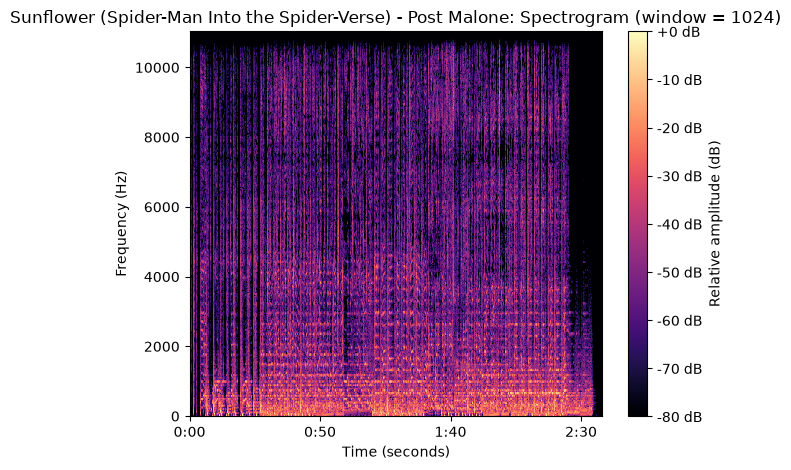

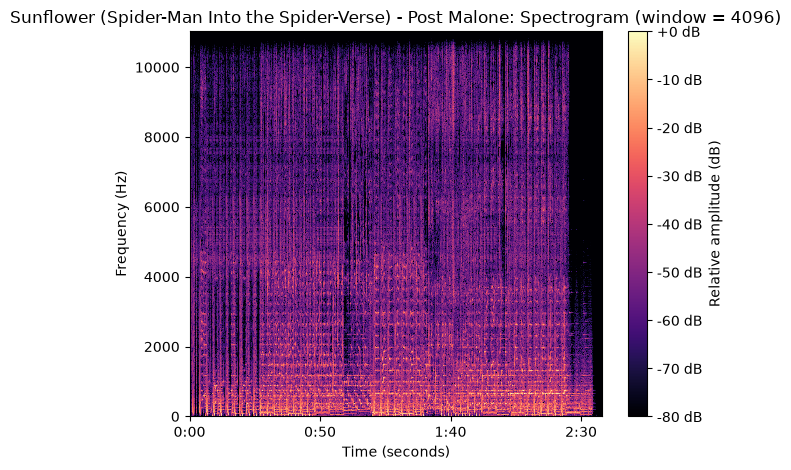

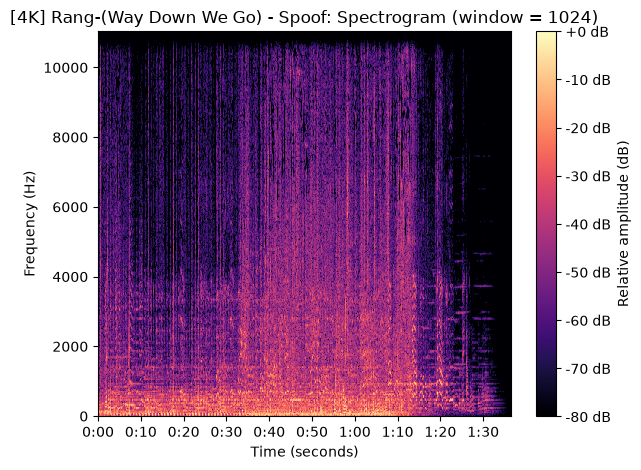

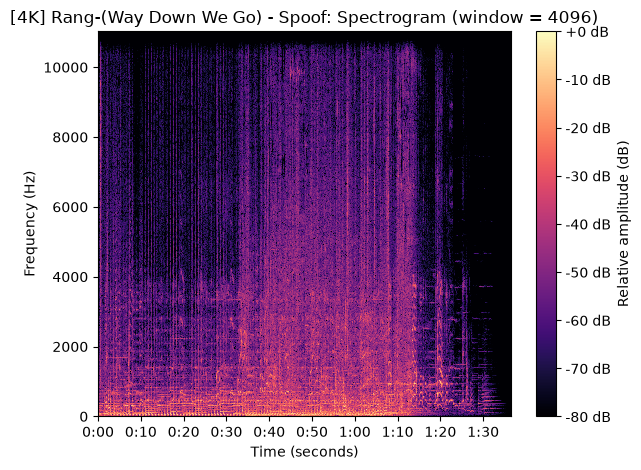

In [13]:

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

WINDOW_SIZES = [1024, 4096]
HOP_LENGTH = 256


def plot_spectrogram(audio, sr, name, n_fft):
    """
    Compute and plot the log-magnitude spectrogram.
    """
    stft = librosa.stft(
        audio,
        n_fft=n_fft,
        hop_length=HOP_LENGTH,
        window="hann"
    )

    magnitude = np.abs(stft)

    # Convert amplitude to decibels
    db = librosa.amplitude_to_db(
        magnitude,
        ref=np.max
    )

    librosa.display.specshow(
        db,
        sr=sr,
        hop_length=HOP_LENGTH,
        x_axis="time",
        y_axis="hz",
        cmap="magma"
    )

    plt.colorbar(
        format="%+2.0f dB",
        label="Relative amplitude (dB)"
    )

    plt.title(
        f"{name}: Spectrogram (window = {n_fft})"
    )
    plt.xlabel("Time (seconds)")
    plt.ylabel("Frequency (Hz)")
    plt.tight_layout()
    plt.show()


for name, audio in songs.items():
    for window_size in WINDOW_SIZES:
        plot_spectrogram(
            audio,
            TARGET_SR,
            name,
            window_size
        )



Threshold = 6 dB, minimum spacing = 50 Hz


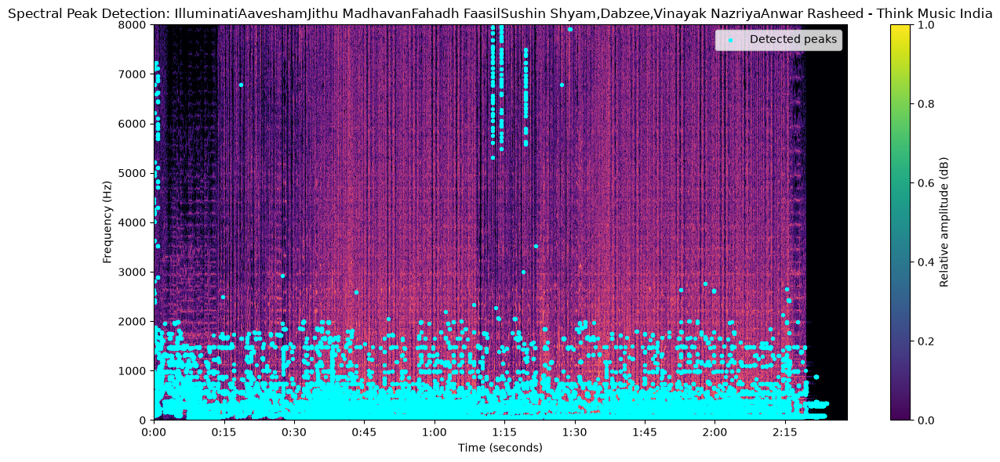


IlluminatiAaveshamJithu MadhavanFahadh FaasilSushin Shyam,Dabzee,Vinayak NazriyaAnwar Rasheed - Think Music India
Detected peak points: 31868

Threshold = 12 dB, minimum spacing = 100 Hz


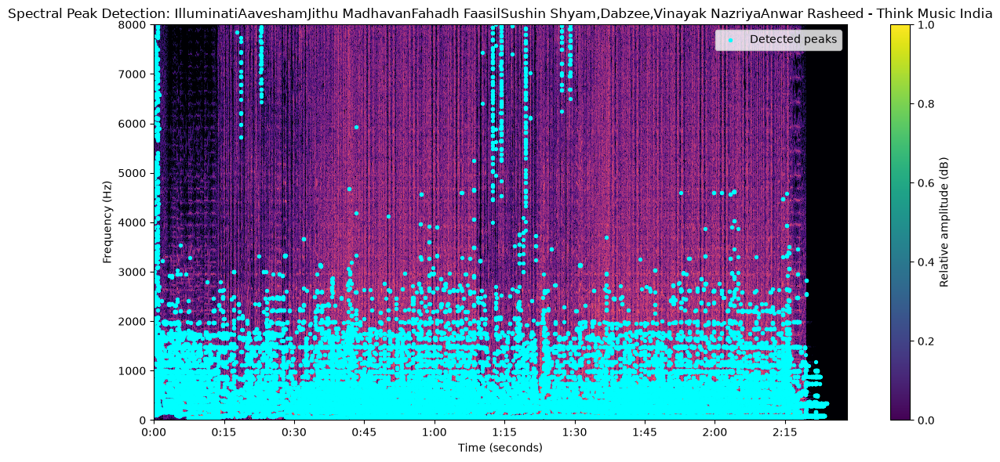


IlluminatiAaveshamJithu MadhavanFahadh FaasilSushin Shyam,Dabzee,Vinayak NazriyaAnwar Rasheed - Think Music India
Detected peak points: 55123

Threshold = 20 dB, minimum spacing = 200 Hz


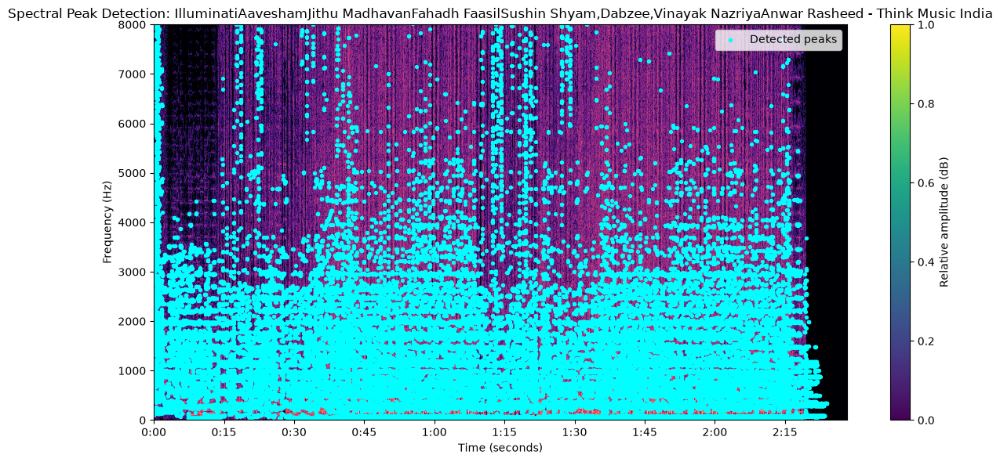


IlluminatiAaveshamJithu MadhavanFahadh FaasilSushin Shyam,Dabzee,Vinayak NazriyaAnwar Rasheed - Think Music India
Detected peak points: 85718

Threshold = 6 dB, minimum spacing = 50 Hz


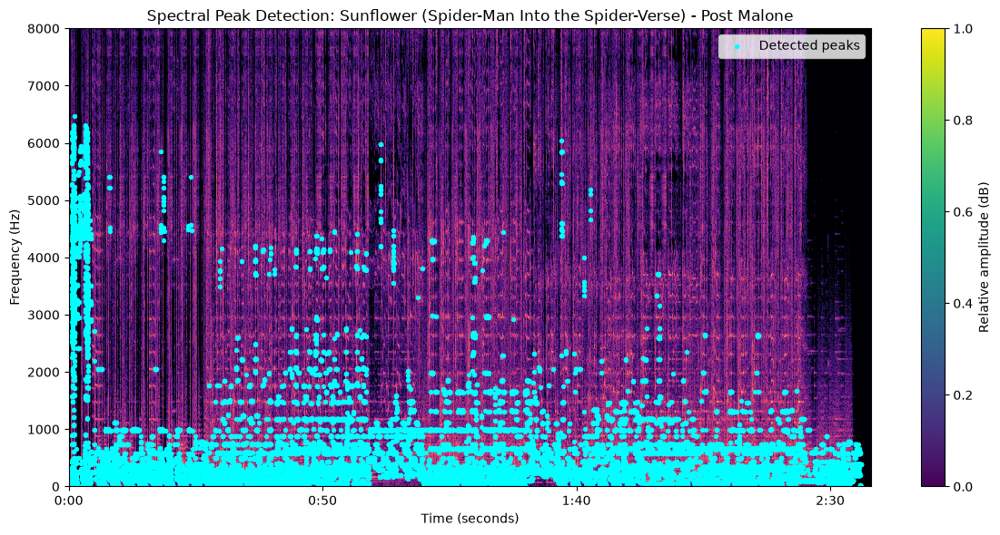


Sunflower (Spider-Man Into the Spider-Verse) - Post Malone
Detected peak points: 38072

Threshold = 12 dB, minimum spacing = 100 Hz


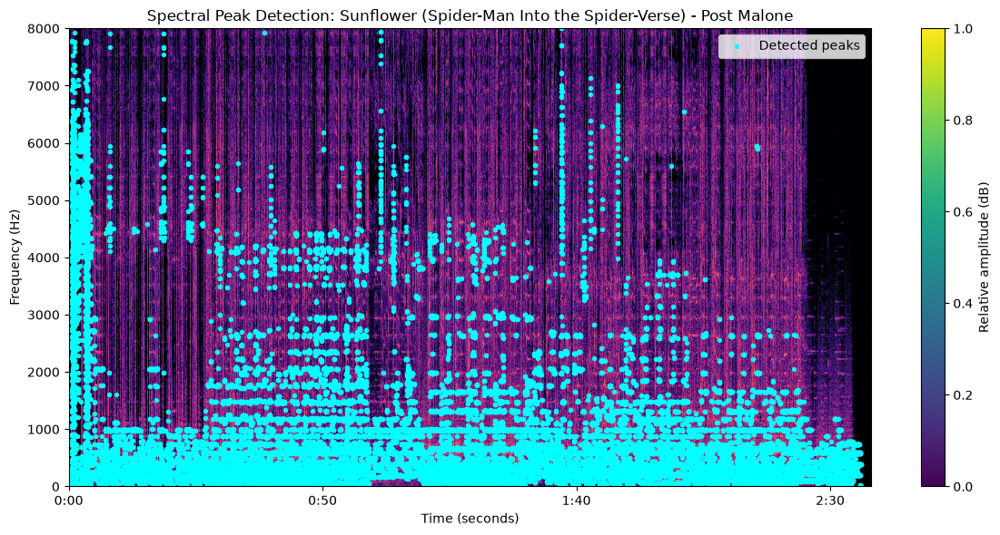


Sunflower (Spider-Man Into the Spider-Verse) - Post Malone
Detected peak points: 63105

Threshold = 20 dB, minimum spacing = 200 Hz


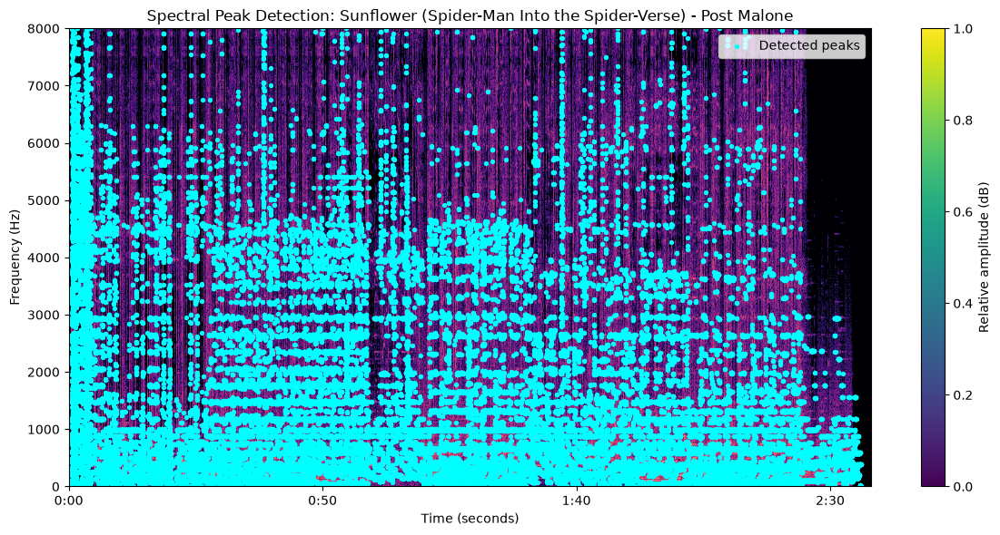


Sunflower (Spider-Man Into the Spider-Verse) - Post Malone
Detected peak points: 90823

Threshold = 6 dB, minimum spacing = 50 Hz


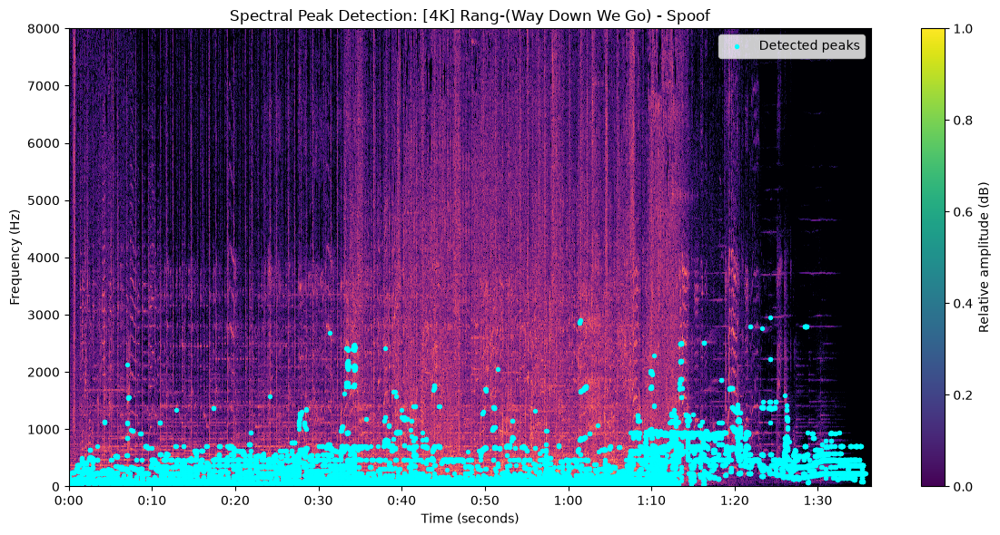


[4K] Rang-(Way Down We Go) - Spoof
Detected peak points: 19038

Threshold = 12 dB, minimum spacing = 100 Hz


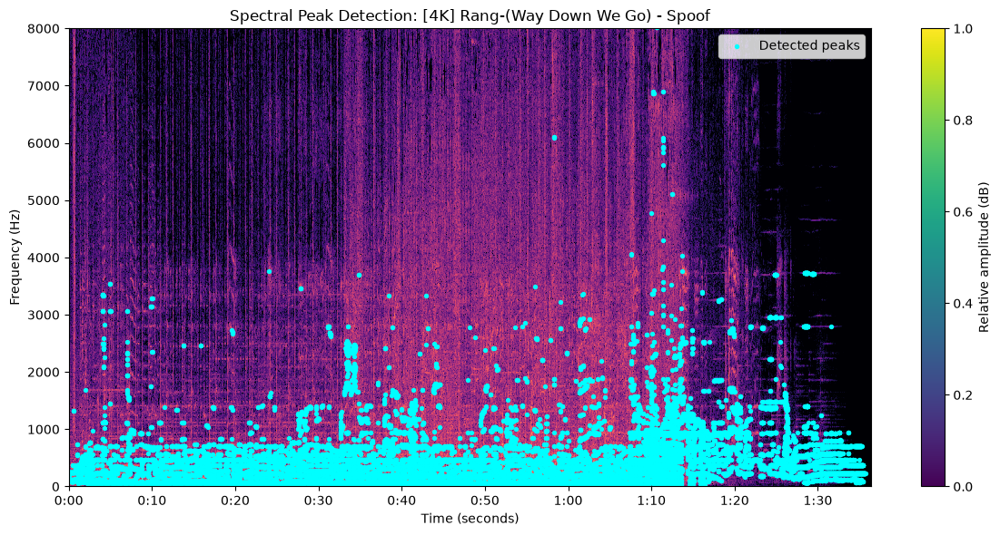


[4K] Rang-(Way Down We Go) - Spoof
Detected peak points: 29642

Threshold = 20 dB, minimum spacing = 200 Hz


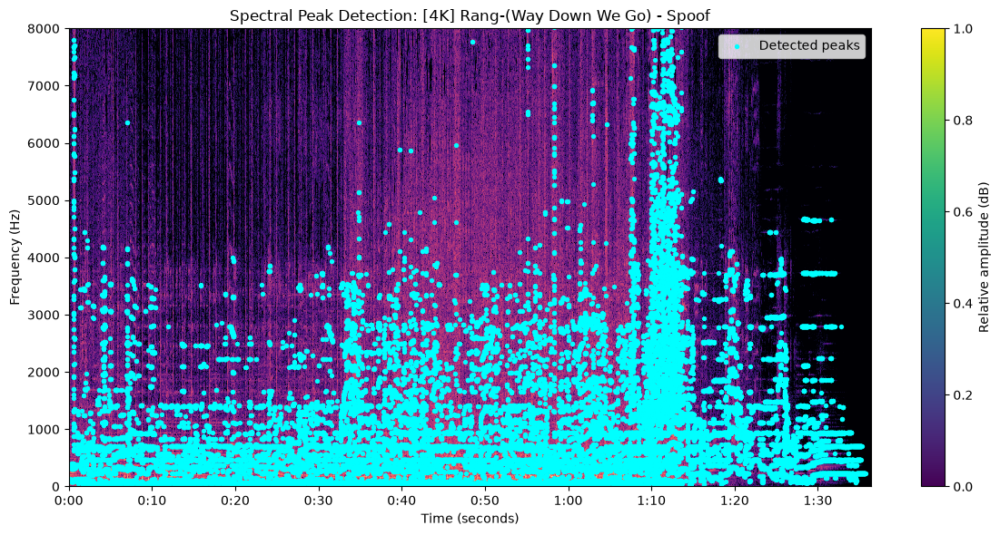


[4K] Rang-(Way Down We Go) - Spoof
Detected peak points: 42841


In [14]:
#3 of Part1
#spectral peak detection
from scipy.signal import find_peaks
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np


def detect_spectral_peaks(
    audio,
    sr,
    name,
    n_fft=2048,
    hop_length=256,
    threshold_db=12,
    min_spacing_hz=100
):
    """
    Detect local frequency maxima in each STFT frame.

    threshold_db:
        Minimum peak strength below the strongest
        frequency in that frame, in decibels.

    min_spacing_hz:
        Minimum allowed distance between peaks.
    """

    stft = librosa.stft(
        audio,
        n_fft=n_fft,
        hop_length=hop_length,
        window="hann"
    )

    magnitude = np.abs(stft)

    db = librosa.amplitude_to_db(
        magnitude,
        ref=np.max
    )

    frequencies = librosa.fft_frequencies(
        sr=sr,
        n_fft=n_fft
    )

    times = librosa.frames_to_time(
        np.arange(db.shape[1]),
        sr=sr,
        hop_length=hop_length
    )

    # Convert minimum spacing in Hz to frequency bins.
    bin_spacing = sr / n_fft

    min_distance_bins = max(
        1,
        int(np.ceil(min_spacing_hz / bin_spacing))
    )

    peak_times = []
    peak_frequencies = []

    for frame_index in range(db.shape[1]):
        spectrum = db[:, frame_index]

        # Ignore the zero-frequency (DC) component.
        spectrum = spectrum.copy()
        spectrum[0] = -np.inf

        # Find the strongest frequency in this frame.
        strongest_db = np.max(spectrum)

        if not np.isfinite(strongest_db):
            continue

        # Relative threshold for this frame.
        peak_indices, properties = find_peaks(
            spectrum,
            height=strongest_db - threshold_db,
            distance=min_distance_bins
        )

        peak_times.extend(
            [times[frame_index]] * len(peak_indices)
        )

        peak_frequencies.extend(
            frequencies[peak_indices]
        )

    # Plot spectrogram and selected peaks.
    plt.figure(figsize=(12, 6))

    librosa.display.specshow(
        db,
        sr=sr,
        hop_length=hop_length,
        x_axis="time",
        y_axis="hz",
        cmap="magma"
    )

    plt.scatter(
        peak_times,
        peak_frequencies,
        s=8,
        color="cyan",
        label="Detected peaks"
    )

    plt.ylim(0, min(8000, sr / 2))
    plt.colorbar(label="Relative amplitude (dB)")
    plt.title(f"Spectral Peak Detection: {name}")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Frequency (Hz)")
    # plt.legend()
    # plt.tight_layout()
    # plt.show()
    plt.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.show()

    print(f"\n{name}")
    print(f"Detected peak points: {len(peak_frequencies)}")

    return np.array(peak_times), np.array(peak_frequencies)


# Experiment with different thresholds and spacings.
for name, audio in songs.items():

    for threshold, spacing in [
        (6, 50),
        (12, 100),
        (20, 200)
    ]:
        print(
            f"\nThreshold = {threshold} dB, "
            f"minimum spacing = {spacing} Hz"
        )

        times, frequencies = detect_spectral_peaks(
            audio,
            TARGET_SR,
            name,
            n_fft=2048,
            hop_length=256,
            threshold_db=threshold,
            min_spacing_hz=spacing
        )



Processing: IlluminatiAaveshamJithu MadhavanFahadh FaasilSushin Shyam,Dabzee,Vinayak NazriyaAnwar Rasheed - Think Music India
Detected peaks: 16,957
Fingerprints retained: 100,000


,time1,frequency1,frequency2,time_separation
0,0.0,4995.703125,279.931641,0.11610
1,0.0,2433.251953,279.931641,0.11610
2,0.0,807.495117,279.931641,0.11610
3,0.0,4995.703125,247.631836,0.11610
4,0.0,2433.251953,247.631836,0.11610
5,0.0,807.495117,247.631836,0.11610
6,0.0,4995.703125,150.732422,0.11610
7,0.0,2433.251953,150.732422,0.11610
8,0.0,807.495117,150.732422,0.11610
9,0.0,4995.703125,462.963867,0.13932



Processing: Sunflower (Spider-Man Into the Spider-Verse) - Post Malone
Detected peaks: 19,219
Fingerprints retained: 100,000


,time1,frequency1,frequency2,time_separation
0,0.0,947.460938,1410.424805,0.11610
1,0.0,1291.992188,1410.424805,0.11610
2,0.0,807.495117,1410.424805,0.11610
3,0.0,947.460938,226.098633,0.11610
4,0.0,1291.992188,226.098633,0.11610
5,0.0,807.495117,226.098633,0.11610
6,0.0,947.460938,269.165039,0.11610
7,0.0,1291.992188,269.165039,0.11610
8,0.0,807.495117,269.165039,0.11610
9,0.0,947.460938,3262.280273,0.13932



Processing: [4K] Rang-(Way Down We Go) - Spoof
Detected peaks: 11,720
Fingerprints retained: 100,000


,time1,frequency1,frequency2,time_separation
0,0.0,53.833008,247.631836,0.11610
1,0.0,86.132812,247.631836,0.11610
2,0.0,118.432617,247.631836,0.11610
3,0.0,53.833008,86.132812,0.11610
4,0.0,86.132812,86.132812,0.11610
5,0.0,118.432617,86.132812,0.11610
6,0.0,53.833008,118.432617,0.11610
7,0.0,86.132812,118.432617,0.11610
8,0.0,118.432617,118.432617,0.11610
9,0.0,53.833008,247.631836,0.13932


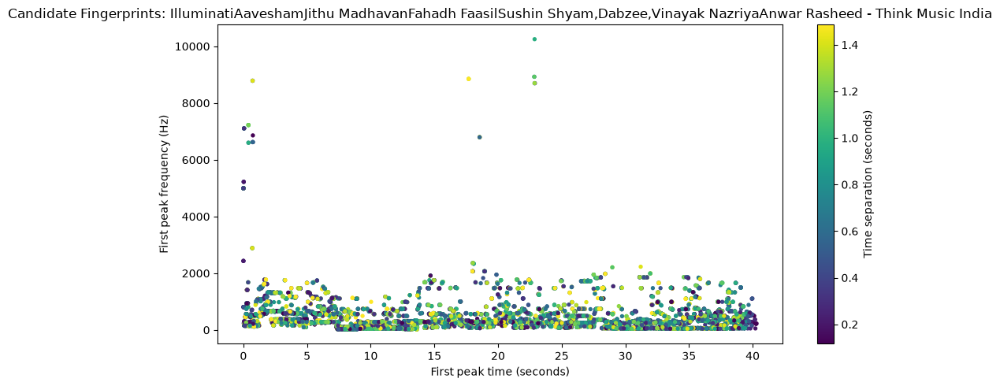

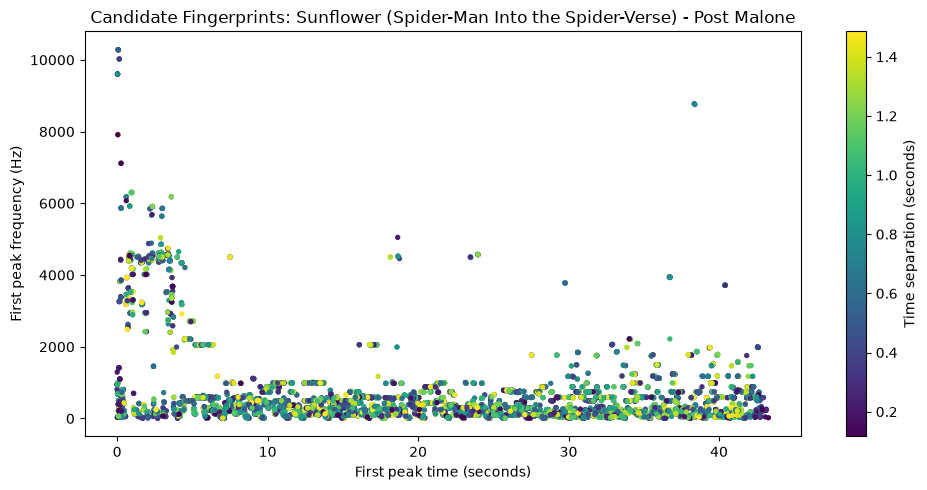

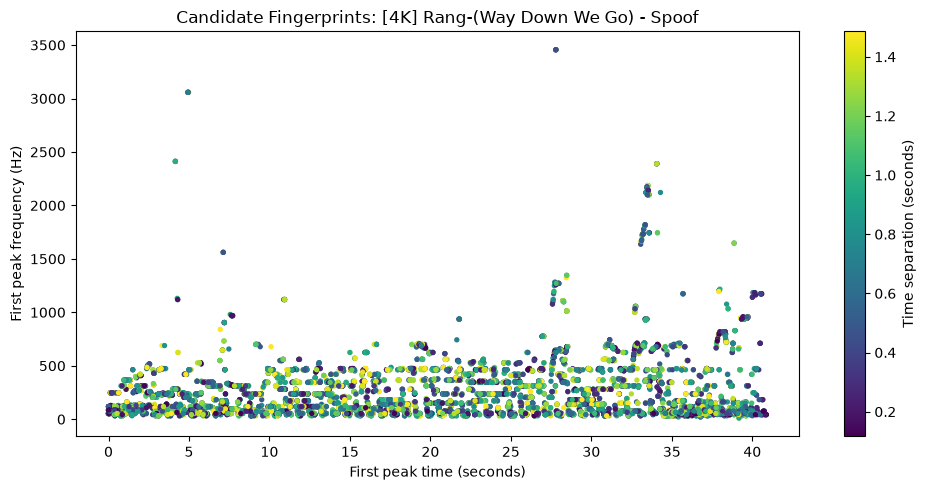

In [15]:

import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from collections import deque


# ============================================================
# MEMORY SETTINGS — adjust these if needed
# ============================================================

N_FFT = 2048
HOP_LENGTH = 512           # Fewer frames than hop_length=256
MAX_PEAKS_PER_FRAME = 3
THRESHOLD_DB = 12

CHUNK_FRAMES = 2048        # Process this many STFT frames at a time
MIN_DT = 0.1
MAX_DT = 1.5

MAX_PAIRS_PER_PEAK = 20    # Limit fingerprints per anchor peak
MAX_FINGERPRINTS = 100_000 # Hard limit per song
MAX_PLOT_POINTS = 10_000
MAX_TABLE_ROWS = 10


# ============================================================
# CHUNKED SPECTRAL PEAK EXTRACTION
# ============================================================

def extract_spectral_peaks(
    audio,
    sr=22050,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    threshold_db=THRESHOLD_DB,
    max_peaks_per_frame=MAX_PEAKS_PER_FRAME,
    chunk_frames=CHUNK_FRAMES
):
    """Extract peaks without constructing a full-song spectrogram."""

    audio = np.asarray(audio, dtype=np.float32)
    audio = np.nan_to_num(audio)

    if len(audio) < n_fft:
        return []

    frequencies = librosa.fft_frequencies(sr=sr, n_fft=n_fft)
    peaks = []

    total_frames = 1 + (len(audio) - n_fft) // hop_length

    for start_frame in range(0, total_frames, chunk_frames):
        count = min(chunk_frames, total_frames - start_frame)

        start_sample = start_frame * hop_length
        end_sample = start_sample + n_fft + (count - 1) * hop_length

        chunk = audio[start_sample:end_sample]

        # center=False ensures chunks don't add padded duplicate frames.
        stft = librosa.stft(
            chunk,
            n_fft=n_fft,
            hop_length=hop_length,
            window="hann",
            center=False
        )

        # Work with one frame at a time; avoid allocating a full dB array.
        for local_frame in range(stft.shape[1]):
            magnitude = np.abs(stft[:, local_frame])
            peak_magnitude = magnitude.max()

            if peak_magnitude <= 0:
                continue

            # Relative threshold in dB, calculated for this frame.
            threshold = peak_magnitude * 10 ** (-threshold_db / 20)

            indices, _ = find_peaks(
                magnitude,
                height=threshold,
                distance=2
            )

            # Exclude DC.
            indices = indices[indices > 0]

            if len(indices) == 0:
                continue

            # Retain the strongest few peaks.
            strongest = indices[
                np.argsort(magnitude[indices])[-max_peaks_per_frame:]
            ]

            frame_number = start_frame + local_frame
            time = frame_number * hop_length / sr

            for idx in strongest:
                strength_db = 20 * np.log10(
                    max(magnitude[idx] / peak_magnitude, 1e-12)
                )
                peaks.append((
                    time,
                    float(frequencies[idx]),
                    float(strength_db)
                ))

        del stft

    return peaks


# ============================================================
# MEMORY-LIMITED FINGERPRINT GENERATION
# ============================================================

def make_fingerprints(
    peaks,
    min_dt=MIN_DT,
    max_dt=MAX_DT,
    max_pairs_per_peak=MAX_PAIRS_PER_PEAK,
    max_fingerprints=MAX_FINGERPRINTS
):
    """
    Pair each peak with a limited number of later peaks.
    Stops when the fingerprint limit is reached.
    """

    fingerprints = []
    recent = deque()

    for t1, f1, strength1 in peaks:

        # Keep only peaks inside the time-separation window.
        while recent and t1 - recent[0][0] > max_dt:
            recent.popleft()

        # Limit the number of pairs generated from this anchor.
        candidates = [
            p for p in recent
            if t1 - p[0] >= min_dt
        ]

        if len(candidates) > max_pairs_per_peak:
            # Evenly sample candidate peaks instead of keeping all pairs.
            positions = np.linspace(
                0, len(candidates) - 1,
                max_pairs_per_peak,
                dtype=int
            )
            candidates = [candidates[i] for i in positions]

        for t2, f2, strength2 in candidates:
            fingerprints.append({
                "time1": t2,
                "frequency1": f2,
                "frequency2": f1,
                "time_separation": t1 - t2
            })

            if len(fingerprints) >= max_fingerprints:
                return fingerprints

        recent.append((t1, f1, strength1))

    return fingerprints


# ============================================================
# PROCESS SONGS
# ============================================================

fingerprints_by_song = {}
peaks_by_song = {}

for name, audio in songs.items():
    print(f"\nProcessing: {name}")

    peaks = extract_spectral_peaks(audio, TARGET_SR)

    fingerprints = make_fingerprints(peaks)

    peaks_by_song[name] = peaks
    fingerprints_by_song[name] = fingerprints

    print(f"Detected peaks: {len(peaks):,}")
    print(f"Fingerprints retained: {len(fingerprints):,}")

    # Display only a small sample.
    if fingerprints:
        display(pd.DataFrame(
            fingerprints[:MAX_TABLE_ROWS]
        ))


# ============================================================
# PLOT A RANDOM SAMPLE, NOT THE ENTIRE DATASET
# ============================================================

rng = np.random.default_rng(42)

for name, fingerprints in fingerprints_by_song.items():

    if not fingerprints:
        print(f"No fingerprints found for {name}")
        continue

    # Avoid building a DataFrame from the entire list.
    sample_size = min(MAX_PLOT_POINTS, len(fingerprints))

    if len(fingerprints) > sample_size:
        indices = rng.choice(
            len(fingerprints),
            size=sample_size,
            replace=False
        )
        sample = [fingerprints[i] for i in indices]
    else:
        sample = fingerprints

    df = pd.DataFrame(sample)

    plt.figure(figsize=(10, 5))

    scatter = plt.scatter(
        df["time1"],
        df["frequency1"],
        c=df["time_separation"],
        s=8,
        cmap="viridis"
    )

    plt.colorbar(scatter, label="Time separation (seconds)")
    plt.title(f"Candidate Fingerprints: {name}")
    plt.xlabel("First peak time (seconds)")
    plt.ylabel("First peak frequency (Hz)")
    plt.tight_layout()
    plt.show()

    del df, sample


In [18]:
#5
import numpy as np
import librosa


def average_spectral_features(
    audio,
    sr=22050,
    n_fft=2048,
    hop_length=512
):
    """Create a normalized average spectral feature vector."""

    stft = librosa.stft(
        audio,
        n_fft=n_fft,
        hop_length=hop_length
    )

    magnitude = np.abs(stft)

    # Average each frequency bin over all time frames.
    average_spectrum = np.mean(magnitude, axis=1)

    # Log compression reduces the influence of very
    # strong frequency components.
    feature = np.log1p(average_spectrum)

    # L2 normalization.
    norm = np.linalg.norm(feature)

    if norm > 0:
        feature = feature / norm

    return feature


def cosine_similarity(a, b):
    """Cosine similarity between two feature vectors."""

    denominator = np.linalg.norm(a) * np.linalg.norm(b)

    if denominator == 0:
        return 0.0

    return float(np.dot(a, b) / denominator)


# Build the reference database.
reference_features = {
    name: average_spectral_features(
        audio, TARGET_SR
    )
    for name, audio in songs.items()
}


def recognize_spectral(query_audio):
    """Identify the most similar reference song."""

    query_features = average_spectral_features(
        query_audio, TARGET_SR
    )

    scores = {
        name: cosine_similarity(
            query_features, reference
        )
        for name, reference in reference_features.items()
    }

    ranked = sorted(
        scores.items(),
        key=lambda item: item[1],
        reverse=True
    )

    best_song, best_score = ranked[0]

    return best_song, best_score, scores


# Test using tester/test1.mp3.
query_audio, _ = librosa.load(
    "tester/test2.mp3",
    sr=TARGET_SR,
    mono=True
)

predicted_song, similarity, all_scores = (
    recognize_spectral(query_audio)
)

print("Test file: tester/test2.mp3")
print("Predicted song:", predicted_song)
print(f"Similarity score: {similarity:.4f}")

print("\nAll similarity scores:")
for name, score in sorted(
    all_scores.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{name}: {score:.4f}")# Example: recognize a clip taken from song 1.
# Replace this with a separate query recording when available.
query_audio = next(iter(songs.values()))

predicted_song, similarity, all_scores = (
    recognize_spectral(query_audio)
)

print("Predicted song:", predicted_song)
print(f"Similarity score: {similarity:.4f}")

print("\nAll similarity scores:")
for name, score in sorted(
    all_scores.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{name}: {score:.4f}")


Test file: tester/test2.mp3
Predicted song: [4K] Rang-(Way Down We Go) - Spoof
Similarity score: 0.9880

All similarity scores:
[4K] Rang-(Way Down We Go) - Spoof: 0.9880
IlluminatiAaveshamJithu MadhavanFahadh FaasilSushin Shyam,Dabzee,Vinayak NazriyaAnwar Rasheed - Think Music India: 0.9785
Sunflower (Spider-Man Into the Spider-Verse) - Post Malone: 0.9666
Predicted song: IlluminatiAaveshamJithu MadhavanFahadh FaasilSushin Shyam,Dabzee,Vinayak NazriyaAnwar Rasheed - Think Music India
Similarity score: 1.0000

All similarity scores:
IlluminatiAaveshamJithu MadhavanFahadh FaasilSushin Shyam,Dabzee,Vinayak NazriyaAnwar Rasheed - Think Music India: 1.0000
Sunflower (Spider-Man Into the Spider-Verse) - Post Malone: 0.9766
[4K] Rang-(Way Down We Go) - Spoof: 0.9557


Unique fingerprint hashes: 48437
Indexed fingerprint occurrences: 300000
Predicted song: IlluminatiAaveshamJithu MadhavanFahadh FaasilSushin Shyam,Dabzee,Vinayak NazriyaAnwar Rasheed - Think Music India
Strongest offset-bin vote count: 71405
Estimated reference offset: 30.0 seconds


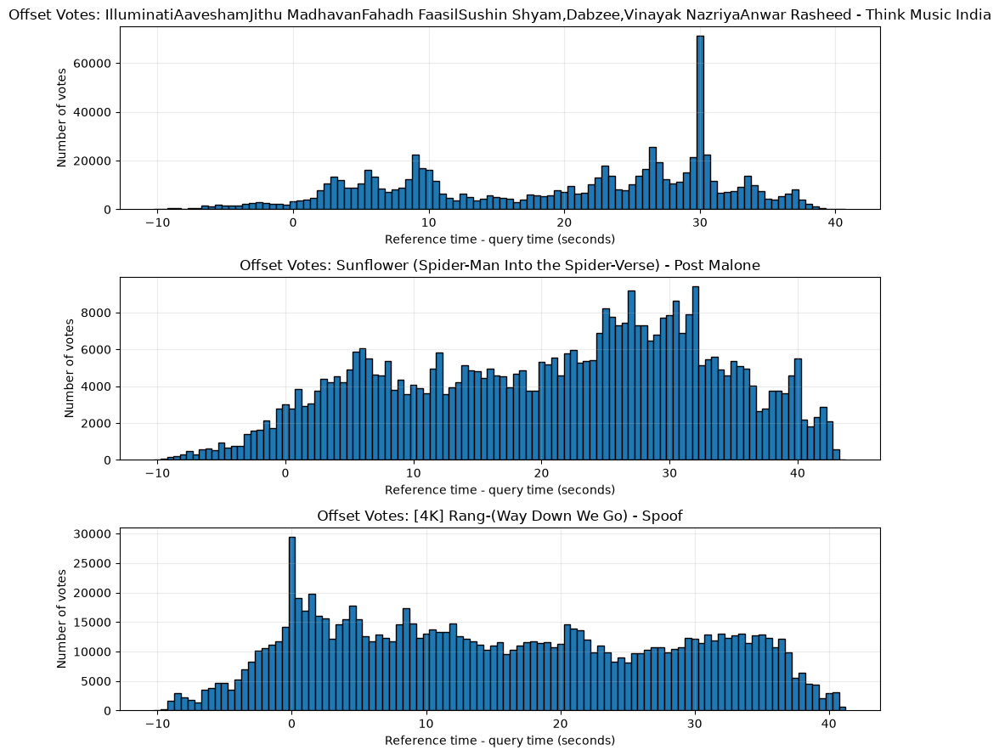

In [4]:
#6

from collections import defaultdict, Counter
import numpy as np
import matplotlib.pyplot as plt


def fingerprint_hashes(
    peaks,
    min_dt=0.1,
    max_dt=1.5,
    frequency_step=20,
    time_step=0.1
):
    """
    Convert peak pairs into compact, quantized hash keys.

    Each key contains:
        first frequency bin,
        second frequency bin,
        time-separation bin.

    The associated value is the first peak's time.
    """

    results = []

    for item in make_fingerprints(
        peaks,
        min_dt=min_dt,
        max_dt=max_dt
    ):
        f1 = item["frequency1"]
        f2 = item["frequency2"]
        dt = item["time_separation"]
        anchor_time = item["time1"]

        key = (
            int(round(f1 / frequency_step)),
            int(round(f2 / frequency_step)),
            int(round(dt / time_step))
        )

        results.append((key, anchor_time))

    return results


# Build an index of reference fingerprints.
# Each hash points to all locations where it occurs.
fingerprint_index = defaultdict(list)

for song_name, peaks in peaks_by_song.items():

    entries = fingerprint_hashes(peaks)

    for key, anchor_time in entries:
        fingerprint_index[key].append(
            (song_name, anchor_time)
        )

print("Unique fingerprint hashes:", len(fingerprint_index))
print("Indexed fingerprint occurrences:", sum(
    len(locations)
    for locations in fingerprint_index.values()
))


def recognize_fingerprint(query_audio, sr=22050):
    """
    Recognize a query clip using fingerprint matching.

    Returns the predicted song, its vote count,
    and the offset-voting histogram.
    """

    query_peaks = extract_spectral_peaks(
        query_audio,
        sr=sr,
        n_fft=2048,
        hop_length=256,
        threshold_db=12,
        max_peaks_per_frame=5
    )

    query_hashes = fingerprint_hashes(query_peaks)

    # (song, quantized offset) -> vote count
    votes = Counter()

    # Collect all offsets for plotting.
    offsets_by_song = defaultdict(list)

    for key, query_time in query_hashes:

        for song_name, reference_time in fingerprint_index.get(
            key, []
        ):
            offset = reference_time - query_time

            # Quantize offsets into half-second bins.
            offset_bin = int(round(offset / 0.5))

            votes[(song_name, offset_bin)] += 1
            offsets_by_song[song_name].append(offset)

    if not votes:
        return None, 0, {}, offsets_by_song

    # Find the strongest song/offset combination.
    (best_song, best_offset_bin), best_votes = (
        votes.most_common(1)[0]
    )

    histogram = {
        name: Counter(
            int(round(offset / 0.5))
            for offset in offsets
        )
        for name, offsets in offsets_by_song.items()
    }

    return best_song, best_votes, histogram, offsets_by_song


def plot_offset_histogram(offsets_by_song):
    """Plot offset votes separately for each reference song."""

    if not offsets_by_song:
        print("No fingerprint matches were found.")
        return

    names = list(songs.keys())

    fig, axes = plt.subplots(
        len(names),
        1,
        figsize=(10, 3 * len(names)),
        squeeze=False
    )

    for ax, name in zip(axes[:, 0], names):

        offsets = offsets_by_song.get(name, [])

        if offsets:
            bins = np.arange(
                np.floor(min(offsets) / 0.5) * 0.5 - 0.25,
                np.ceil(max(offsets) / 0.5) * 0.5 + 0.75,
                0.5
            )

            ax.hist(
                offsets,
                bins=bins,
                edgecolor="black"
            )
        else:
            ax.text(
                0.5, 0.5,
                "No matches",
                ha="center",
                va="center",
                transform=ax.transAxes
            )

        ax.set_title(f"Offset Votes: {name}")
        ax.set_xlabel("Reference time - query time (seconds)")
        ax.set_ylabel("Number of votes")
        ax.grid(True, alpha=0.25)

    plt.tight_layout()
    plt.show()


# Example query: a 10-second clip from a reference song.
reference_name = next(iter(songs))
reference_audio = songs[reference_name]

start_seconds = 30
clip_seconds = 10

start = int(start_seconds * TARGET_SR)
end = int((start_seconds + clip_seconds) * TARGET_SR)

query_audio = reference_audio[start:end]

if len(query_audio) == 0:
    raise ValueError("The selected query segment is empty.")

predicted, vote_count, histogram, offsets = (
    recognize_fingerprint(query_audio, TARGET_SR)
)

print("Predicted song:", predicted)
print("Strongest offset-bin vote count:", vote_count)

if predicted is not None:
    winning_bins = histogram[predicted]
    best_bin = max(winning_bins, key=winning_bins.get)

    print(
        "Estimated reference offset:",
        f"{best_bin * 0.5:.1f} seconds"
    )

plot_offset_histogram(offsets)


 query_length      method  correct  accuracy_percent
            3 Fingerprint 0.777778         77.777778
            3    Spectral 0.888889         88.888889
            5 Fingerprint 1.000000        100.000000
            5    Spectral 0.777778         77.777778
           10 Fingerprint 1.000000        100.000000
           10    Spectral 0.888889         88.888889
           15 Fingerprint 1.000000        100.000000
           15    Spectral 0.888889         88.888889


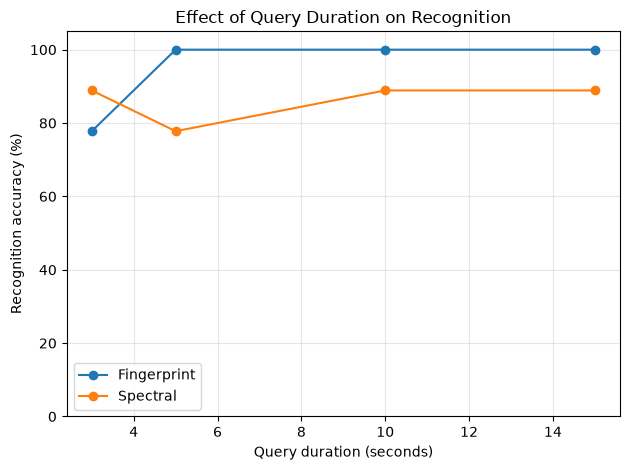


Accuracy by starting position:
 start_seconds      method  correct
      0.000000 Fingerprint 1.000000
      0.000000    Spectral 0.583333
     20.352007 Fingerprint 1.000000
     20.352007    Spectral 1.000000
     21.602007 Fingerprint 1.000000
     21.602007    Spectral 1.000000
     22.852007 Fingerprint 1.000000
     22.852007    Spectral 1.000000
     23.352007 Fingerprint 1.000000
     23.352007    Spectral 1.000000
     33.306009 Fingerprint 1.000000
     33.306009    Spectral 1.000000
     34.556009 Fingerprint 1.000000
     34.556009    Spectral 1.000000
     35.766009 Fingerprint 1.000000
     35.766009    Spectral 1.000000
     35.806009 Fingerprint 1.000000
     35.806009    Spectral 1.000000
     36.306009 Fingerprint 1.000000
     36.306009    Spectral 1.000000
     37.016009 Fingerprint 1.000000
     37.016009    Spectral 1.000000
     38.266009 Fingerprint 1.000000
     38.266009    Spectral 1.000000
     38.766009 Fingerprint 0.000000
     38.766009    Spectral 1.000

In [5]:
#8

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def predict_both(query):
    """Run both recognizers and return their predictions."""

    spectral_song, spectral_score, _ = recognize_spectral(query)

    fingerprint_song, fingerprint_votes, _, _ = (
        recognize_fingerprint(query, TARGET_SR)
    )

    return {
        "Spectral": spectral_song,
        "Fingerprint": fingerprint_song
    }


def get_query(audio, start_seconds, duration_seconds, sr):
    """Extract a query clip safely from an audio array."""

    start = int(start_seconds * sr)
    end = int((start_seconds + duration_seconds) * sr)

    if start < 0 or end > len(audio) or end <= start:
        return None

    return audio[start:end]


def evaluate_query_lengths(
    songs,
    sr,
    durations=(3, 5, 10, 15),
    start_fractions=(0.0, 0.25, 0.5)
):
    results = []

    for true_song, audio in songs.items():

        song_duration = len(audio) / sr

        for query_length in durations:

            if query_length > song_duration:
                continue

            # Start at the beginning, 25%, and 50%
            # of the usable starting-position range.
            max_start = song_duration - query_length

            for fraction in start_fractions:
                start_seconds = fraction * max_start

                query = get_query(
                    audio,
                    start_seconds,
                    query_length,
                    sr
                )

                if query is None:
                    continue

                predictions = predict_both(query)

                for method, prediction in predictions.items():
                    results.append({
                        "true_song": true_song,
                        "query_length": query_length,
                        "start_seconds": start_seconds,
                        "method": method,
                        "prediction": prediction,
                        "correct": prediction == true_song
                    })

    return pd.DataFrame(results)


length_results = evaluate_query_lengths(
    songs,
    TARGET_SR
)

# Accuracy for each duration.
length_summary = (
    length_results
    .groupby(["query_length", "method"])["correct"]
    .mean()
    .reset_index()
)

length_summary["accuracy_percent"] = (
    length_summary["correct"] * 100
)

print(length_summary.to_string(index=False))

# Plot recognition accuracy against query duration.
for method in length_summary["method"].unique():

    subset = length_summary[
        length_summary["method"] == method
    ]

    plt.plot(
        subset["query_length"],
        subset["accuracy_percent"],
        marker="o",
        label=method
    )

plt.xlabel("Query duration (seconds)")
plt.ylabel("Recognition accuracy (%)")
plt.title("Effect of Query Duration on Recognition")
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Examine starting-position effects.
start_summary = (
    length_results
    .groupby(["start_seconds", "method"])["correct"]
    .mean()
    .reset_index()
)

print("\nAccuracy by starting position:")
print(start_summary.to_string(index=False))


 snr_db      method  correct  accuracy_percent
     -5 Fingerprint 1.000000        100.000000
     -5    Spectral 0.333333         33.333333
      0 Fingerprint 1.000000        100.000000
      0    Spectral 0.333333         33.333333
     10 Fingerprint 1.000000        100.000000
     10    Spectral 0.333333         33.333333
     20 Fingerprint 1.000000        100.000000
     20    Spectral 0.666667         66.666667
     30 Fingerprint 1.000000        100.000000
     30    Spectral 1.000000        100.000000


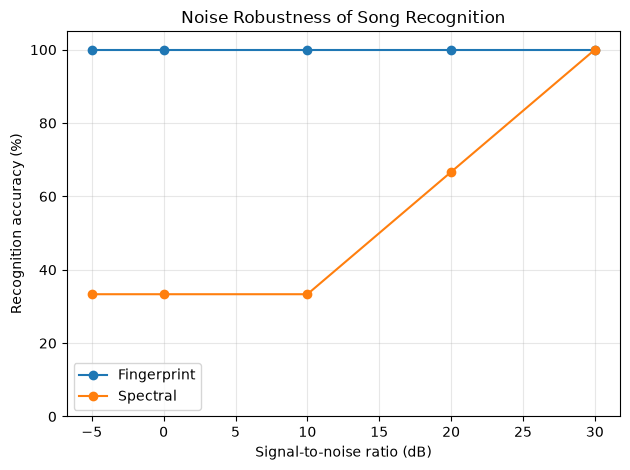

In [6]:
#9

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def add_noise_at_snr(audio, snr_db, rng):
    """Add Gaussian noise at a specified SNR in decibels."""

    audio = np.asarray(audio, dtype=float)

    signal_power = np.mean(audio ** 2)

    if signal_power < 1e-12:
        return audio.copy()

    noise = rng.normal(size=len(audio))
    noise_power = np.mean(noise ** 2)

    target_noise_power = (
        signal_power / (10 ** (snr_db / 10))
    )

    noise = noise * np.sqrt(
        target_noise_power / noise_power
    )

    return audio + noise


def evaluate_noise_robustness(
    songs,
    sr,
    snr_levels=(30, 20, 10, 0, -5),
    query_length=10,
    trials=3,
    seed=42
):
    results = []
    rng = np.random.default_rng(seed)

    for true_song, audio in songs.items():

        duration = len(audio) / sr

        if duration < query_length:
            continue

        # Use a fixed, reproducible query position.
        start = (duration - query_length) / 2

        clean_query = get_query(
            audio, start, query_length, sr
        )

        for snr_db in snr_levels:

            for trial in range(trials):

                noisy_query = add_noise_at_snr(
                    clean_query,
                    snr_db,
                    rng
                )

                predictions = predict_both(noisy_query)

                for method, prediction in predictions.items():
                    results.append({
                        "true_song": true_song,
                        "snr_db": snr_db,
                        "trial": trial + 1,
                        "method": method,
                        "prediction": prediction,
                        "correct": prediction == true_song
                    })

    return pd.DataFrame(results)


noise_results = evaluate_noise_robustness(
    songs,
    TARGET_SR
)

noise_summary = (
    noise_results
    .groupby(["snr_db", "method"])["correct"]
    .mean()
    .reset_index()
)

noise_summary["accuracy_percent"] = (
    noise_summary["correct"] * 100
)

print(noise_summary.to_string(index=False))

# Plot accuracy versus SNR.
for method in noise_summary["method"].unique():

    subset = noise_summary[
        noise_summary["method"] == method
    ].sort_values("snr_db")

    plt.plot(
        subset["snr_db"],
        subset["accuracy_percent"],
        marker="o",
        label=method
    )

plt.xlabel("Signal-to-noise ratio (dB)")
plt.ylabel("Recognition accuracy (%)")
plt.title("Noise Robustness of Song Recognition")
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


/usr/lib/python3.14/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/usr/lib/python3.14/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/usr/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)
/usr/lib/python3.14/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/usr/lib/python3.14/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is

transformation  setting      method  correct  accuracy_percent
   Pitch shift     -2.0 Fingerprint 0.666667         66.666667
   Pitch shift     -2.0    Spectral 1.000000        100.000000
   Pitch shift     -1.0 Fingerprint 1.000000        100.000000
   Pitch shift     -1.0    Spectral 0.666667         66.666667
   Pitch shift      0.0 Fingerprint 1.000000        100.000000
   Pitch shift      0.0    Spectral 1.000000        100.000000
   Pitch shift      1.0 Fingerprint 0.666667         66.666667
   Pitch shift      1.0    Spectral 0.666667         66.666667
   Pitch shift      2.0 Fingerprint 0.333333         33.333333
   Pitch shift      2.0    Spectral 1.000000        100.000000
  Time stretch      0.8 Fingerprint 1.000000        100.000000
  Time stretch      0.8    Spectral 1.000000        100.000000
  Time stretch      0.9 Fingerprint 1.000000        100.000000
  Time stretch      0.9    Spectral 1.000000        100.000000
  Time stretch      1.0 Fingerprint 1.000000        100

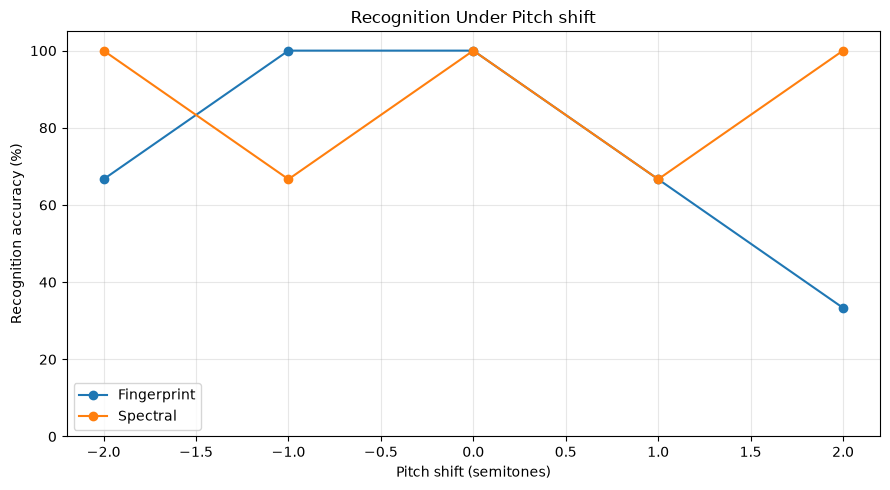

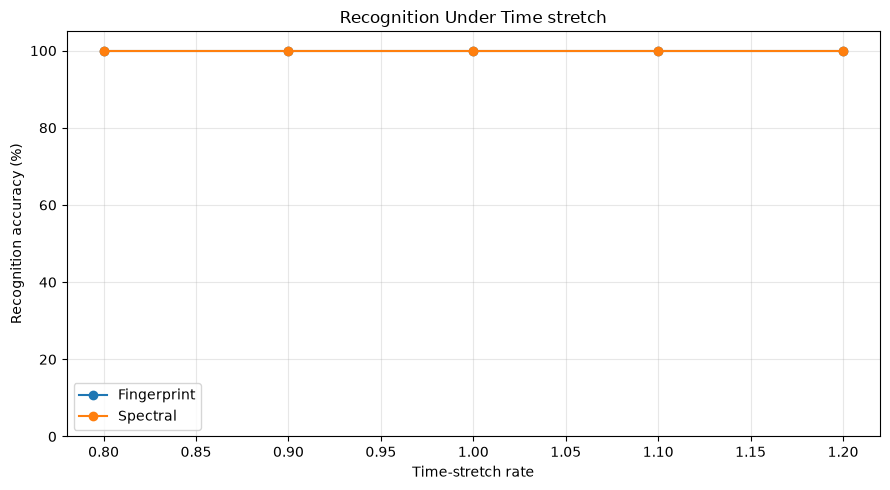

In [7]:
#10
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def evaluate_transformations(
    songs,
    sr,
    query_length=10,
    pitch_shifts=(-2, -1, 0, 1, 2),
    stretch_rates=(0.8, 0.9, 1.0, 1.1, 1.2)
):
    results = []

    for true_song, audio in songs.items():

        duration = len(audio) / sr

        if duration < query_length:
            continue

        # Select a segment from the middle of the song.
        start = (duration - query_length) / 2

        original = get_query(
            audio, start, query_length, sr
        )

        # Pitch-shifting experiments.
        for semitones in pitch_shifts:

            transformed = librosa.effects.pitch_shift(
                y=original,
                sr=sr,
                n_steps=semitones
            )

            predictions = predict_both(transformed)

            for method, prediction in predictions.items():
                results.append({
                    "true_song": true_song,
                    "transformation": "Pitch shift",
                    "setting": semitones,
                    "method": method,
                    "prediction": prediction,
                    "correct": prediction == true_song
                })

        # Time-stretching experiments.
        for rate in stretch_rates:

            transformed = librosa.effects.time_stretch(
                y=original,
                rate=rate
            )

            predictions = predict_both(transformed)

            for method, prediction in predictions.items():
                results.append({
                    "true_song": true_song,
                    "transformation": "Time stretch",
                    "setting": rate,
                    "method": method,
                    "prediction": prediction,
                    "correct": prediction == true_song
                })

    return pd.DataFrame(results)


transformation_results = evaluate_transformations(
    songs,
    TARGET_SR
)

transformation_summary = (
    transformation_results
    .groupby(
        ["transformation", "setting", "method"]
    )["correct"]
    .mean()
    .reset_index()
)

transformation_summary["accuracy_percent"] = (
    transformation_summary["correct"] * 100
)

print(transformation_summary.to_string(index=False))


# Separate plots because pitch shift and stretch
# use different units on their horizontal axes.
for transformation in ["Pitch shift", "Time stretch"]:

    subset_all = transformation_summary[
        transformation_summary["transformation"]
        == transformation
    ]

    plt.figure(figsize=(9, 5))

    for method in subset_all["method"].unique():

        subset = subset_all[
            subset_all["method"] == method
        ].sort_values("setting")

        plt.plot(
            subset["setting"],
            subset["accuracy_percent"],
            marker="o",
            label=method
        )

    if transformation == "Pitch shift":
        plt.xlabel("Pitch shift (semitones)")
    else:
        plt.xlabel("Time-stretch rate")

    plt.ylabel("Recognition accuracy (%)")
    plt.title(f"Recognition Under {transformation}")
    plt.ylim(0, 105)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
